### Librerias

In [164]:
# Se importan librerias permitidas para resolver el problema
import numpy as np
import matplotlib.pyplot as plt

### Carga de datos

In [165]:
# Se usa la forma que se muestra en el enunciado
datos = np.load("../datos/datos_P1.npz")

matriz_a = datos["A"]
vector_b = datos["b"]


## B.- Reconstrucción

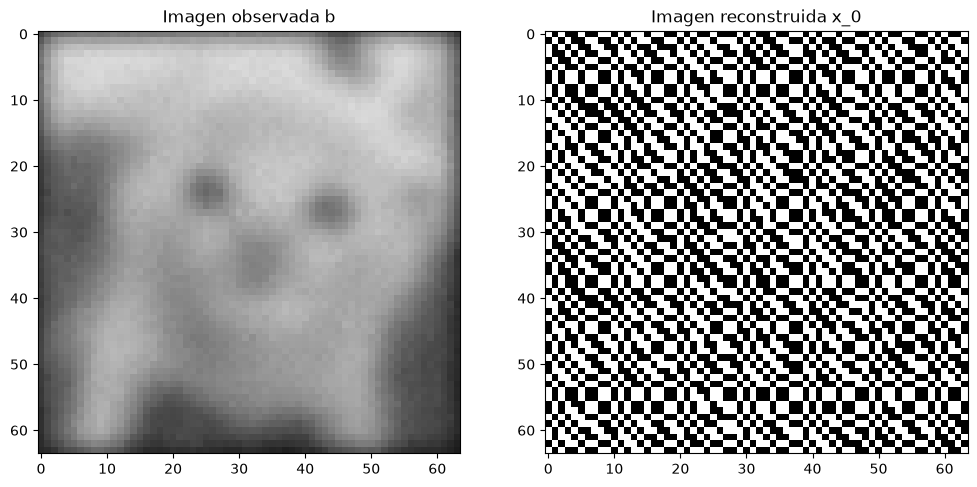

In [166]:
# I.-
# Calculamos x_0, para esto resolvemos el sistema lineal
# En el enunciado se menciona que se puede utilizar np.linalg.solve
x_0 = np.linalg.solve(matriz_a, vector_b)

# Comparamos la reconstrucción con la imagen observada
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(vector_b.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Imagen observada b")
ax[1].imshow(x_0.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Imagen reconstruida x_0")
plt.show()


### Calculamos la norma, max y el residuo

In [167]:
# norma euclidiana
norma_euclidiana_x0 = np.linalg.norm(x_0)

# maximo absoluto de x_0
max_x0 = np.max(np.abs(x_0))

# residuo, para este vamos a calcular la matriz A por x_0
# por lo que vi si se puede usar "@" para multiplicar matrices
residuo = np.linalg.norm(matriz_a @ x_0 - vector_b)

### Revisamos los resultados

In [168]:
print(f"Norma euclidiana de x_0: {norma_euclidiana_x0}")
print(f"Maximo absoluto de x_0: {max_x0}")
print(f"Residuo: {residuo}")

Norma euclidiana de x_0: 992626.416729
Maximo absoluto de x_0: 55257.75733986092
Residuo: 1.5111379587256674e-11


## Regularización de Tikhonov (método ridge)

### Primero creamos los elementos basicos

In [ ]:
# Calculamos la matriz A^tA
AtA = matriz_a.T @ matriz_a

# Calculamos el vector A^tb
Atb = matriz_a.T @ vector_b

# Y la matriz identidad
n = matriz_a.shape[0] 
matriz_identidad = np.eye(n) #https://numpy.org/doc/2.3/reference/generated/numpy.eye.html por lo que vi asi se hace la matriz identidad

### Calculo de las reconstrucciones

In [170]:
# Creamos la matriz del sistema para cada lambda y resolvemos
# Usamos una lista lambda para guardar los valores de lambda que se van a probar
lista_lambda = [10**-3.5, 10**-2.5, 1]
lista_lambda_strings = ["10^-3.5", "10^-2.5", "1"] # para que el print sea mas entendible

resultados = []
for valor_lambda, lambda_string in zip(lista_lambda, lista_lambda_strings):
    matriz_sistema = AtA + valor_lambda * matriz_identidad
    solucion = np.linalg.solve(matriz_sistema, Atb)

    # Calculamos la norma de x_lambda
    norma_x_lambda = np.linalg.norm(solucion)
    # y su residuo
    residuo_x_lambda = np.linalg.norm(matriz_a @ solucion - vector_b)

    # Mostramos los resultados
    print(f"Resultados para lambda = {lambda_string}:")
    print(f"Norma de x_lambda: {norma_x_lambda}")
    print(f"Residuo de x_lambda: {residuo_x_lambda} (delta: 0.64)") # Enunciado pide comparar con delta = 0.64
    print()

    # y por ultimo guardamos la reconstrucción para mostrarla
    resultados.append(solucion)


Resultados para lambda = 10^-3.5:
Norma de x_lambda: 41.135990957686076
Residuo de x_lambda: 0.5545587811349489 (delta: 0.64)

Resultados para lambda = 10^-2.5:
Norma de x_lambda: 40.17481845801241
Residuo de x_lambda: 0.6125143500730488 (delta: 0.64)

Resultados para lambda = 1:
Norma de x_lambda: 19.3344726724977
Residuo de x_lambda: 19.975280603910214 (delta: 0.64)



### Reconstrucción con regularización de Tikhonov

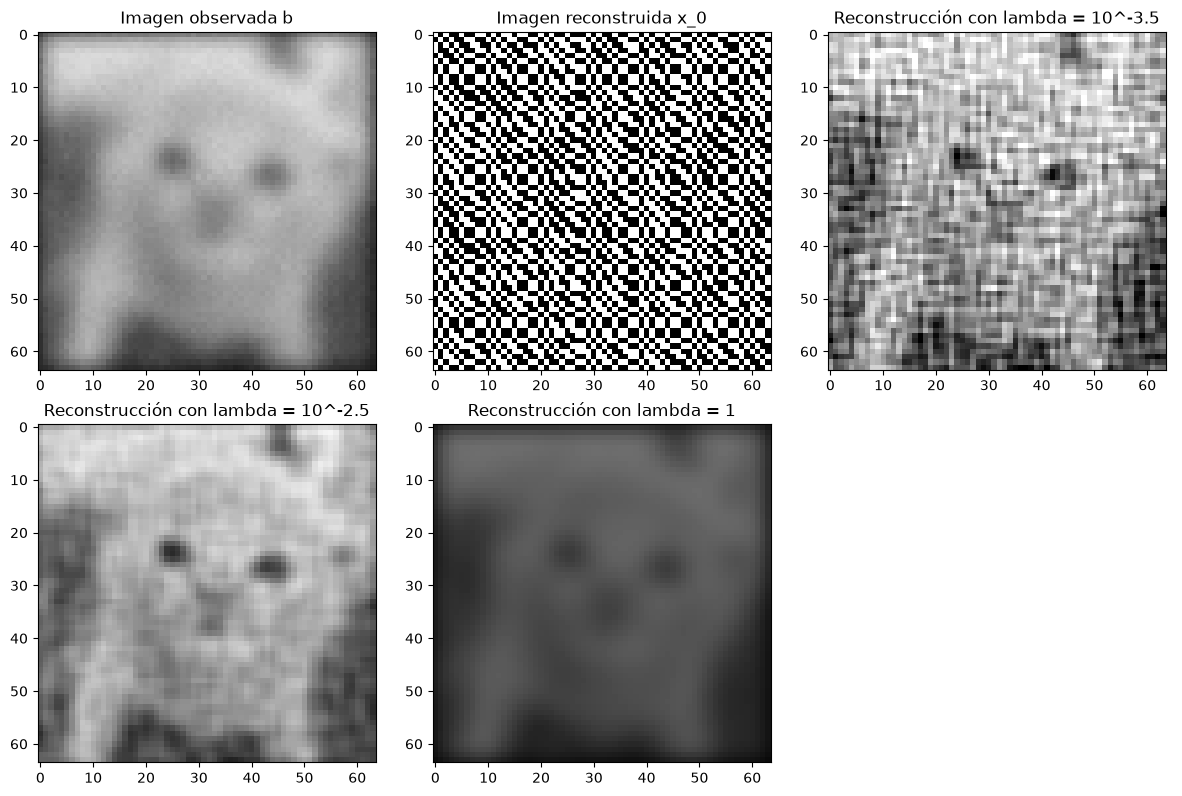

In [171]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
ax = ax.flatten()  # Aplanamos el arreglo de ejes para poder indexarlos facilmente

ax[0].imshow(vector_b.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[0].set_title("Imagen observada b")
ax[1].imshow(x_0.reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[1].set_title("Imagen reconstruida x_0")

# Ahora mostramos las reconstrucciones para cada lambda
ax[2].imshow(resultados[0].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[2].set_title(f"Reconstrucción con lambda = {lista_lambda_strings[0]}")
ax[3].imshow(resultados[1].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[3].set_title(f"Reconstrucción con lambda = {lista_lambda_strings[1]}")
ax[4].imshow(resultados[2].reshape(64, 64), cmap="gray", vmin=0, vmax=1)
ax[4].set_title(f"Reconstrucción con lambda = {lista_lambda_strings[2]}")
ax[5].axis('off')  # Ocultamos el ultimo ya que no tiene imagen

plt.tight_layout()
plt.show()